#Chuẩn bị dữ liệu MNIST


In [3]:
import os
import numpy as np
import matplotlib.pyplot as plt

FILES = {
    "train_images": "train-images.idx3-ubyte",
    "train_labels": "train-labels.idx1-ubyte",
    "test_images":  "t10k-images.idx3-ubyte",
    "test_labels":  "t10k-labels.idx1-ubyte"
}

def load_mnist(data_dir="mnist_data"):
    out = {}
    for key, fname in FILES.items():
        path = os.path.join(data_dir, fname)
        with open(path, "rb") as f:
            buf = f.read()
        if "images" in key:
            out[key] = np.frombuffer(buf, np.uint8, offset=16).reshape(-1, 28 * 28)
        else:
            out[key] = np.frombuffer(buf, np.uint8, offset=8)
    return out

mnist = load_mnist(data_dir="mnist_data")

X_train = mnist["train_images"].astype(np.float64) / 255.0
y_train = mnist["train_labels"].astype(np.int64)
X_test  = mnist["test_images"].astype(np.float64) / 255.0
y_test  = mnist["test_labels"].astype(np.int64)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (60000, 784) | Test: (10000, 784)


#Hàm đánh giá (NumPy)

In [9]:
def confusion_matrix_np(y_true, y_pred, n_classes):
    cm = np.zeros((n_classes, n_classes), dtype=np.int64)
    np.add.at(cm, (y_true, y_pred), 1)          # cm[i, j]: nhãn thật i, dự đoán j
    return cm

def evaluate_np(y_true, y_pred, classes, title=""):
    classes = list(classes)
    cm = confusion_matrix_np(y_true, y_pred, len(classes))
    tp = np.diag(cm).astype(float)
    fp = cm.sum(axis=0) - tp
    fn = cm.sum(axis=1) - tp
    prec = np.divide(tp, tp + fp, out=np.zeros_like(tp), where=(tp + fp) > 0)
    rec  = np.divide(tp, tp + fn, out=np.zeros_like(tp), where=(tp + fn) > 0)
    f1   = np.divide(2 * prec * rec, prec + rec, out=np.zeros_like(tp), where=(prec + rec) > 0)
    print(title)
    print(f"{'Lớp':>5} {'Precision':>10} {'Recall':>8} {'F1':>8}")
    for i, c in enumerate(classes):
        print(f"{c:>5} {prec[i]:>10.4f} {rec[i]:>8.4f} {f1[i]:>8.4f}")
    print(f"Macro {prec.mean():>10.4f} {rec.mean():>8.4f} {f1.mean():>8.4f}")

def plot_loss(losses, title):
    plt.figure(figsize=(6, 3.5))
    plt.plot(range(1, len(losses) + 1), losses)
    plt.xlabel("Epoch"); plt.ylabel("Cross-Entropy loss")
    plt.title(title); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

#Logistic Regression bằng NumPy (chữ số 0 và 1)

In [10]:
class LogisticRegressionNP:
    def __init__(self, lr=0.1, n_epochs=200, seed=0):
        self.lr, self.n_epochs, self.seed = lr, n_epochs, seed

    @staticmethod
    def sigmoid(z):
        return 1.0 / (1.0 + np.exp(-np.clip(z, -500, 500)))

    @staticmethod
    def loss(y, y_hat, eps=1e-12):
        return -np.mean(y * np.log(y_hat + eps) + (1 - y) * np.log(1 - y_hat + eps))

    def fit(self, X, y):
        N, d = X.shape
        self.w = np.random.default_rng(self.seed).normal(0, 0.01, size=d)
        self.b = 0.0
        self.losses = []
        for _ in range(self.n_epochs):
            y_hat = self.sigmoid(X @ self.w + self.b)
            self.losses.append(self.loss(y, y_hat))
            self.w -= self.lr * (X.T @ (y_hat - y) / N)     # Gradient Descent
            self.b -= self.lr * np.mean(y_hat - y)
        return self

    def predict(self, X):
        return (self.sigmoid(X @ self.w + self.b) >= 0.5).astype(np.int64)

mask_tr = (y_train == 0) | (y_train == 1)
mask_te = (y_test == 0) | (y_test == 1)
X_tr01, y_tr01 = X_train[mask_tr], y_train[mask_tr]
X_te01, y_te01 = X_test[mask_te],  y_test[mask_te]

logreg = LogisticRegressionNP(lr=0.1, n_epochs=200).fit(X_tr01, y_tr01.astype(float))

Logistic Regression (NumPy), test 0/1
  Lớp  Precision   Recall       F1
    0     1.0000   0.9980   0.9990
    1     0.9982   1.0000   0.9991
Macro     0.9991   0.9990   0.9990


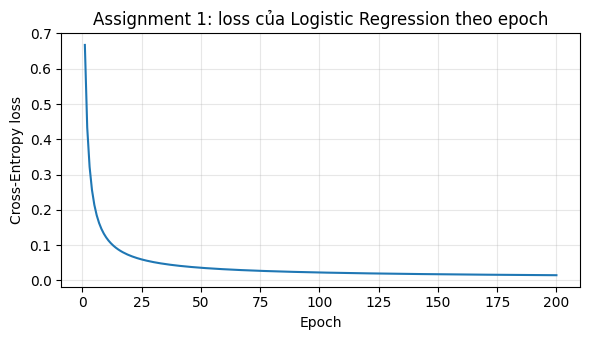

In [11]:
#Đánh giá precision, recall, F1
evaluate_np(y_te01, logreg.predict(X_te01), classes=[0, 1], title="Logistic Regression (NumPy), test 0/1")
#Trực quan hoá loss
plot_loss(logreg.losses, "Assignment 1: loss của Logistic Regression theo epoch")

#Softmax Regression bằng NumPy (10 chữ số)

In [12]:
class SoftmaxRegressionNP:
    def __init__(self, n_classes=10, lr=0.5, n_epochs=300, seed=0):
        self.C, self.lr, self.n_epochs, self.seed = n_classes, lr, n_epochs, seed

    @staticmethod
    def softmax(Z):
        E = np.exp(Z - Z.max(axis=1, keepdims=True))
        return E / E.sum(axis=1, keepdims=True)

    @staticmethod
    def loss(Y, P, eps=1e-12):
        return -np.mean(np.sum(Y * np.log(P + eps), axis=1))

    def fit(self, X, y):
        N, d = X.shape
        Y = np.eye(self.C)[y]
        self.W = np.random.default_rng(self.seed).normal(0, 0.01, size=(d, self.C))
        self.b = np.zeros(self.C)
        self.losses = []
        for _ in range(self.n_epochs):
            P = self.softmax(X @ self.W + self.b)
            self.losses.append(self.loss(Y, P))
            self.W -= self.lr * (X.T @ (P - Y) / N)         # Gradient Descent
            self.b -= self.lr * (P - Y).mean(axis=0)
        return self

    def predict(self, X):
        return np.argmax(self.softmax(X @ self.W + self.b), axis=1)

softmax_reg = SoftmaxRegressionNP(n_classes=10, lr=0.5, n_epochs=300).fit(X_train, y_train)

Softmax Regression (NumPy), test 10 lớp
  Lớp  Precision   Recall       F1
    0     0.9420   0.9776   0.9594
    1     0.9575   0.9727   0.9650
    2     0.9262   0.8760   0.9004
    3     0.8952   0.9050   0.9000
    4     0.9041   0.9308   0.9172
    5     0.9038   0.8531   0.8777
    6     0.9294   0.9489   0.9390
    7     0.9194   0.9105   0.9150
    8     0.8703   0.8747   0.8725
    9     0.8915   0.8880   0.8898
Macro     0.9139   0.9137   0.9136


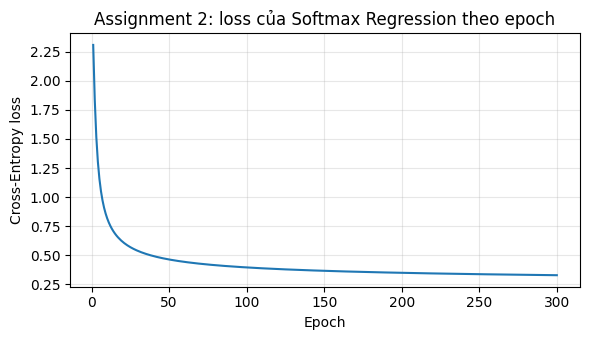

In [13]:
#Đánh giá precision, recall, F1
evaluate_np(y_test, softmax_reg.predict(X_test), classes=range(10), title="Softmax Regression (NumPy), test 10 lớp")
#Trực quan hoá loss
plot_loss(softmax_reg.losses, "Assignment 2: loss của Softmax Regression theo epoch")

#Dùng scikit-learn


In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score, f1_score

# Logistic Regression (0 vs 1)
sk_bin = LogisticRegression(max_iter=1000, random_state=0).fit(X_tr01, y_tr01)
p = sk_bin.predict(X_te01)
print("Logistic Regression (sklearn), test 0/1")
print(f"Precision={precision_score(y_te01, p):.4f}  Recall={recall_score(y_te01, p):.4f}  F1={f1_score(y_te01, p):.4f}")

# Softmax Regression (10 lớp)
sk_soft = LogisticRegression(max_iter=300, random_state=0).fit(X_train, y_train)
p = sk_soft.predict(X_test)
print("\nSoftmax Regression (sklearn), test 10 lớp (macro)")
print(f"Precision={precision_score(y_test, p, average='macro'):.4f}  "
      f"Recall={recall_score(y_test, p, average='macro'):.4f}  "
      f"F1={f1_score(y_test, p, average='macro'):.4f}")

Logistic Regression (sklearn), test 0/1
Precision=0.9991  Recall=1.0000  F1=0.9996

Softmax Regression (sklearn), test 10 lớp (macro)
Precision=0.9248  Recall=0.9247  F1=0.9247
